# Section 1- The Base Algorithm

The algorithm is implemented as a class because fitting produces learned parameters (means, covariances, mixture weights) and diagnostic state (log_likelihoods) that must persist after training and be accessible to subsequent calls like predict. A class cleanly encapsulates this stateful relationship between fitting and inference, while also providing a reusable sklearn-style interface.

In [ ]:
import numpy as np
from scipy.stats import multivariate_normal

class GaussianMixtureEM:
    def __init__(self, K, max_iter=100, tol=1e-6):
        self.K = K
        self.max_iter = max_iter
        self.tol = tol

    def fit(self, X):
        N, D = X.shape
        K = self.K

        # --- Initialization ---
        # Random responsibilities (could also use k-means init)
        rng = np.random.default_rng(42)
        idx = rng.choice(N, K, replace=False)
        self.means = X[idx]                          # (K, D)
        self.covs  = [np.eye(D)] * K                 # (K, D, D)
        self.pis   = np.ones(K) / K                  # (K,)

        self.log_likelihoods = []

        for iteration in range(self.max_iter):

            # ---- E-Step ----
            R = self._e_step(X)          # responsibilities (N, K)

            # ---- M-Step ----
            self._m_step(X, R)

            # ---- Log-likelihood ----
            ll = self._log_likelihood(X)
            self.log_likelihoods.append(ll)

            if iteration > 0 and abs(ll - self.log_likelihoods[-2]) < self.tol:
                print(f"Converged at iteration {iteration}")
                break

        return self

    def _e_step(self, X):
        N = X.shape[0]
        R = np.zeros((N, self.K))
        for k in range(self.K):
            R[:, k] = self.pis[k] * multivariate_normal.pdf(
                X, mean=self.means[k], cov=self.covs[k]
            )
        R /= R.sum(axis=1, keepdims=True)   # normalize rows → valid posteriors
        return R

    def _m_step(self, X, R):
        N = X.shape[0]
        Nk = R.sum(axis=0)                  # effective count per component (K,)

        self.pis   = Nk / N
        self.means = (R.T @ X) / Nk[:, None]

        for k in range(self.K):
            diff = X - self.means[k]        # (N, D)
            self.covs[k] = (R[:, k:k+1] * diff).T @ diff / Nk[k]

    def _log_likelihood(self, X):
        N = X.shape[0]
        ll = 0.0
        for k in range(self.K):
            ll += self.pis[k] * multivariate_normal.pdf(
                X, mean=self.means[k], cov=self.covs[k]
            )
        return np.log(ll + 1e-300).sum()    # small epsilon avoids log(0)

    def predict(self, X):
        """Return hard cluster assignments."""
        return self._e_step(X).argmax(axis=1)

# Section 2- The Modified Algorithm with initialization options

In [ ]:
import numpy as np
from scipy.stats import multivariate_normal
class GaussianMixtureEM:
    def __init__(self, K, max_iter=100, tol=1e-6, init='random', random_state=42):
        self.K = K
        self.max_iter = max_iter
        self.tol = tol
        self.init = init
        self.random_state = random_state  # now accepted and used

    def fit(self, X):
        N, D = X.shape
        K = self.K

        # --- Initialization ---
        rng = np.random.default_rng(self.random_state)  # use random_state, not hardcoded 42
        if self.init == 'kmeans':
            self.means = self._kmeans_init(X, rng)
        else:
            idx = rng.choice(N, K, replace=False)
            self.means = X[idx]

        self.covs = [np.eye(D)] * K
        self.pis  = np.ones(K) / K

        self.log_likelihoods = []

        for iteration in range(self.max_iter):
            R = self._e_step(X)
            self._m_step(X, R)
            ll = self._log_likelihood(X)
            self.log_likelihoods.append(ll)
            if iteration > 0 and abs(ll - self.log_likelihoods[-2]) < self.tol:
                print(f"  Converged at iteration {iteration}")
                break

        return self

    def _kmeans_init(self, X, rng, kmeans_iter=20):
        idx = rng.choice(len(X), self.K, replace=False)
        centers = X[idx].copy()
        for _ in range(kmeans_iter):
            labels = np.argmin(((X[:, None] - centers[None]) ** 2).sum(-1), axis=1)
            new_centers = np.array([
                X[labels == k].mean(axis=0) if (labels == k).any() else centers[k]
                for k in range(self.K)
            ])
            if np.allclose(centers, new_centers):
                break
            centers = new_centers
        return centers

    def _e_step(self, X):
        N = X.shape[0]
        R = np.zeros((N, self.K))
        for k in range(self.K):
            R[:, k] = self.pis[k] * multivariate_normal.pdf(
                X, mean=self.means[k], cov=self.covs[k]
            )
        R /= R.sum(axis=1, keepdims=True)
        return R

    def _m_step(self, X, R):
        N = X.shape[0]
        Nk = R.sum(axis=0)
        self.pis   = Nk / N
        self.means = (R.T @ X) / Nk[:, None]
        for k in range(self.K):
            diff = X - self.means[k]
            self.covs[k] = (R[:, k:k+1] * diff).T @ diff / Nk[k]

    def _log_likelihood(self, X):
        ll = 0.0
        for k in range(self.K):
            ll += self.pis[k] * multivariate_normal.pdf(
                X, mean=self.means[k], cov=self.covs[k]
            )
        return np.log(ll + 1e-300).sum()

    def predict(self, X):
        return self._e_step(X).argmax(axis=1)

For the purpose of comparing the performance of EM with randomized initialization and k-means initialization, a synthetic dataset of 4 2d gaussians was generated such that the clusters were largely overlapping in a way that helps demonstrate the weakness of random initialization in EM.

Fitting EM with random initialization …
Fitting EM with k-means initialization …
  Converged at iteration 168

────────────────────────────────────────────
                            Random    K-Means
────────────────────────────────────────────
  Matched accuracy           0.637      0.832
  Adjusted Rand Index        0.456      0.608
  Final log-likelihood     -2166.7    -2128.8
  Iterations                   200        169
────────────────────────────────────────────


/tmp/ipykernel_8256/2654240786.py:61: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ell   = mpatches.Ellipse(mean, w, h, angle=angle,


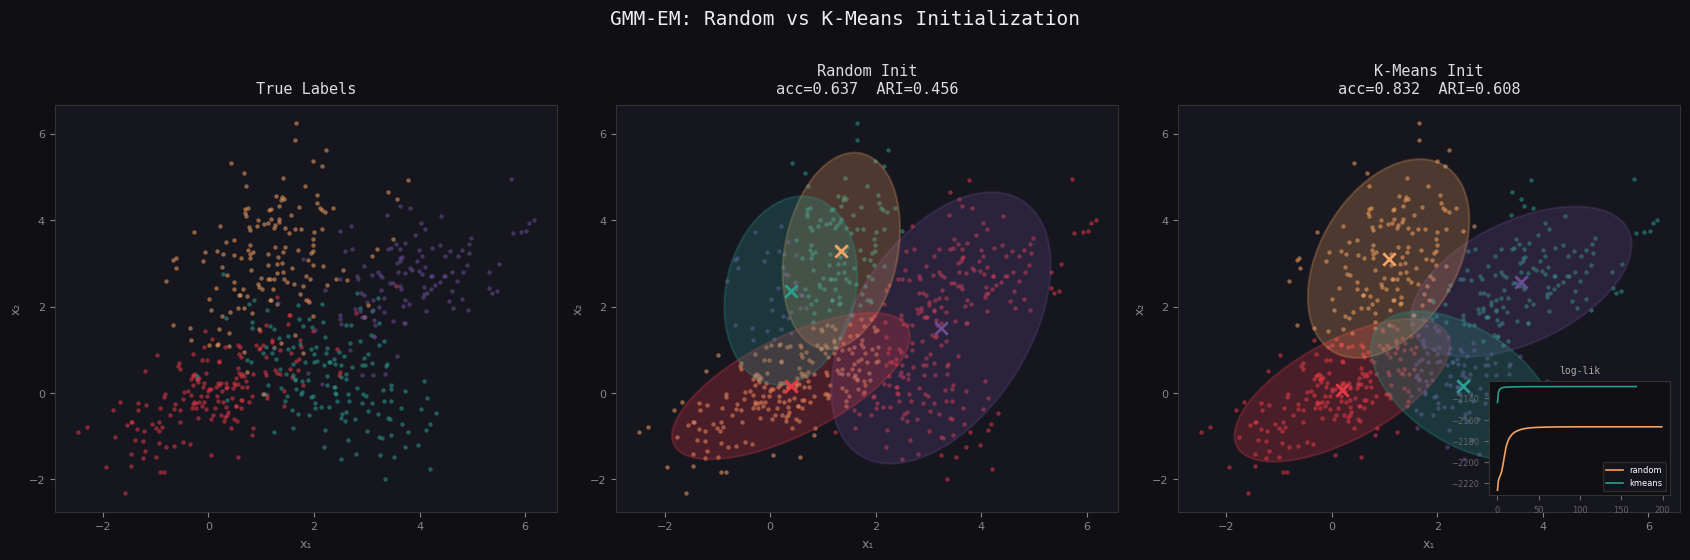


Plot saved → gmm_comparison.png


In [ ]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ─────────────────────────────────────────────
#  Dataset: 4 overlapping 2-D Gaussians
# ─────────────────────────────────────────────
def make_dataset(n=400, seed=0):
    rng = np.random.default_rng(seed)

    means = np.array([
        [0.0, 0.0],
        [2.5, 0.5],
        [1.2, 3.0],
        [3.8, 2.8],
    ])

    covs = [
        np.array([[1.2,  0.7], [0.7,  0.9]]),
        np.array([[1.0, -0.5], [-0.5, 1.1]]),
        np.array([[0.8,  0.3], [0.3,  1.4]]),
        np.array([[1.1,  0.6], [0.6,  0.9]]),
    ]

    pis = [0.3, 0.25, 0.25, 0.20]

    X_parts, y_parts = [], []
    for k, (mu, cov, pi) in enumerate(zip(means, covs, pis)):
        ni = int(n * pi)
        X_parts.append(rng.multivariate_normal(mu, cov, ni))
        y_parts.append(np.full(ni, k))

    X = np.vstack(X_parts)
    y = np.concatenate(y_parts)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]


# ─────────────────────────────────────────────
#  Hungarian-matched accuracy
# ─────────────────────────────────────────────
def matched_accuracy(y_true, y_pred, K):
    confusion = np.zeros((K, K), dtype=int)
    for t, p in zip(y_true, y_pred):
        confusion[t, p] += 1
    row_ind, col_ind = linear_sum_assignment(-confusion)
    correct = confusion[row_ind, col_ind].sum()
    return correct / len(y_true), col_ind


# ─────────────────────────────────────────────
#  Confidence ellipse helper
# ─────────────────────────────────────────────
def plot_ellipse(ax, mean, cov, color, n_std=2.0, alpha=0.25):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    w, h  = 2 * n_std * np.sqrt(vals)
    ell   = mpatches.Ellipse(mean, w, h, angle=angle,
                             color=color, alpha=alpha, lw=1.5,
                             edgecolor=color, facecolor=color)
    ax.add_patch(ell)


# ─────────────────────────────────────────────
#  Main
# ─────────────────────────────────────────────
K = 4
PALETTE = ["#e63946", "#2a9d8f", "#f4a261", "#6a4c93"]

X, y_true = make_dataset(n=600, seed=7)

print("Fitting EM with random initialization …")
em_rand = GaussianMixtureEM(K=K, max_iter=200, tol=1e-6,
                             init="random", random_state=7).fit(X)

print("Fitting EM with k-means initialization …")
em_km   = GaussianMixtureEM(K=K, max_iter=200, tol=1e-6,
                             init="kmeans", random_state=42).fit(X)

pred_rand = em_rand.predict(X)
pred_km   = em_km.predict(X)

acc_rand, perm_rand = matched_accuracy(y_true, pred_rand, K)
acc_km,   perm_km   = matched_accuracy(y_true, pred_km,   K)
ari_rand  = adjusted_rand_score(y_true, pred_rand)
ari_km    = adjusted_rand_score(y_true, pred_km)

print(f"\n{'':─<44}")
print(f"  {'':22}  {'Random':>8}   {'K-Means':>8}")
print(f"{'':─<44}")
print(f"  {'Matched accuracy':22}  {acc_rand:>8.3f}   {acc_km:>8.3f}")
print(f"  {'Adjusted Rand Index':22}  {ari_rand:>8.3f}   {ari_km:>8.3f}")
print(f"  {'Final log-likelihood':22}  {em_rand.log_likelihoods[-1]:>8.1f}   "
      f"{em_km.log_likelihoods[-1]:>8.1f}")
print(f"  {'Iterations':22}  {len(em_rand.log_likelihoods):>8d}   "
      f"{len(em_km.log_likelihoods):>8d}")
print(f"{'':─<44}")


# ─────────────────────────────────────────────
#  Plot
# ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
fig.patch.set_facecolor("#0f0f14")
for ax in axes:
    ax.set_facecolor("#16161f")
    ax.tick_params(colors="#888", labelsize=8)
    for sp in ax.spines.values():
        sp.set_edgecolor("#333")

titles = [
    "True Labels",
    f"Random Init\nacc={acc_rand:.3f}  ARI={ari_rand:.3f}",
    f"K-Means Init\nacc={acc_km:.3f}  ARI={ari_km:.3f}",
]

datasets = [
    (y_true,    None,      None),
    (pred_rand, em_rand,   perm_rand),
    (pred_km,   em_km,     perm_km),
]

for ax, title, (labels, model, perm) in zip(axes, titles, datasets):
    for k in range(K):
        mask = labels == k
        col  = PALETTE[k]
        ax.scatter(X[mask, 0], X[mask, 1],
                   c=col, s=10, alpha=0.55, linewidths=0, rasterized=True)

    if model is not None:
        inv_perm = np.argsort(perm)
        for k in range(K):
            true_k = inv_perm[k]
            col    = PALETTE[true_k]
            plot_ellipse(ax, model.means[k], model.covs[k], col)
            ax.scatter(*model.means[k], marker="x", s=80,
                       c=col, linewidths=2, zorder=5)

    ax.set_title(title, color="#dddddd", fontsize=11,
                 fontfamily="monospace", pad=8)
    ax.set_xlabel("x₁", color="#888", fontsize=9)
    ax.set_ylabel("x₂", color="#888", fontsize=9)

# log-likelihood convergence inset
ax_ll = axes[2].inset_axes([0.62, 0.04, 0.36, 0.28])
ax_ll.set_facecolor("#0f0f14")
ax_ll.plot(em_rand.log_likelihoods, color="#f4a261", lw=1.2, label="random")
ax_ll.plot(em_km.log_likelihoods,   color="#2a9d8f", lw=1.2, label="kmeans")
ax_ll.set_title("log-lik", color="#aaa", fontsize=7, fontfamily="monospace")
ax_ll.tick_params(colors="#666", labelsize=6)
for sp in ax_ll.spines.values():
    sp.set_edgecolor("#333")
ax_ll.legend(fontsize=6, labelcolor="white",
             facecolor="#16161f", edgecolor="#333")

fig.suptitle("GMM-EM: Random vs K-Means Initialization",
             color="#eeeeee", fontsize=14, fontfamily="monospace", y=1.01)
plt.tight_layout()
#plt.savefig("/mnt/user-data/outputs/gmm_comparison.png",
            #dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("\nPlot saved → gmm_comparison.png")

Running AIC/BIC sweep (K = 1 … 8) …

  AIC selects K = 7
  BIC selects K = 4

───────────────────────────────────────────────────────
                                AIC-best     BIC-best
───────────────────────────────────────────────────────
  Selected K                           7            4
  AIC score                       4299.0       4303.6
  BIC score                       4479.3       4404.7
  Matched accuracy             N/A (K≠4)   0.8316666666666667
  Adjusted Rand Index              0.422        0.608
  Final log-likelihood           -2108.5      -2128.8
  Iterations                         300          171
───────────────────────────────────────────────────────


/tmp/ipykernel_8256/825020155.py:152: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ell   = mpatches.Ellipse(mean, w, h, angle=angle,


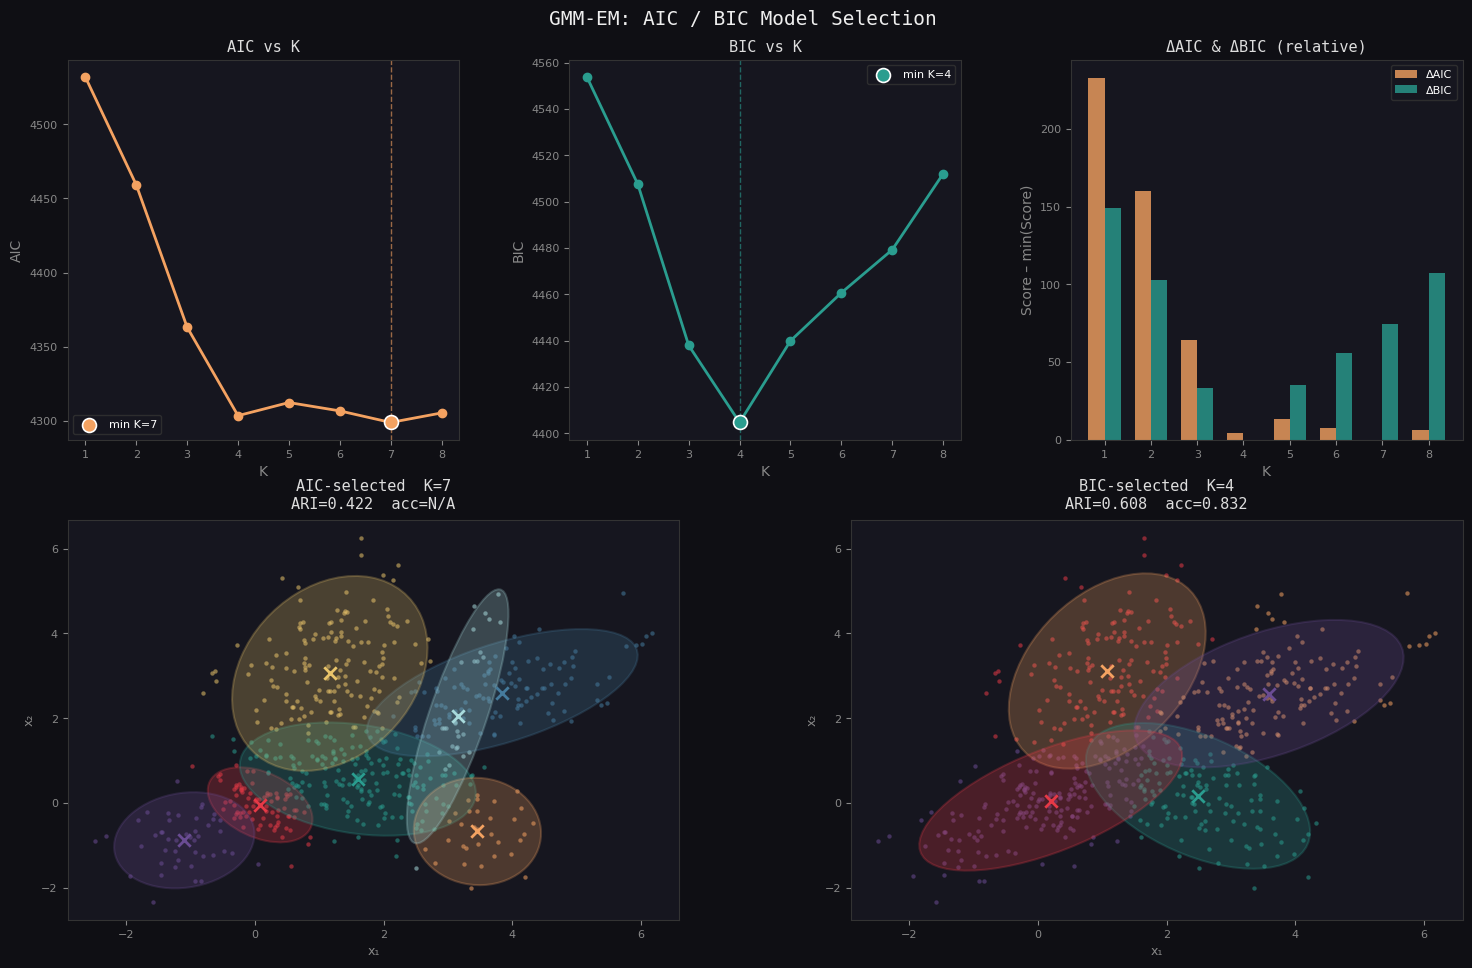


Plot saved → gmm_model_selection.png


In [ ]:
import numpy as np
from scipy.stats import multivariate_normal
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# ─────────────────────────────────────────────
#  Your existing GaussianMixtureEM (unchanged)
# ─────────────────────────────────────────────
class GaussianMixtureEM:
    def __init__(self, K, max_iter=100, tol=1e-6, init='random', random_state=42):
        self.K = K
        self.max_iter = max_iter
        self.tol = tol
        self.init = init
        self.random_state = random_state

    def fit(self, X):
        N, D = X.shape
        K = self.K
        rng = np.random.default_rng(self.random_state)
        if self.init == 'kmeans':
            self.means = self._kmeans_init(X, rng)
        else:
            idx = rng.choice(N, K, replace=False)
            self.means = X[idx]

        self.covs = [np.eye(D)] * K
        self.pis  = np.ones(K) / K
        self.log_likelihoods = []

        for iteration in range(self.max_iter):
            R = self._e_step(X)
            self._m_step(X, R)
            ll = self._log_likelihood(X)
            self.log_likelihoods.append(ll)
            if iteration > 0 and abs(ll - self.log_likelihoods[-2]) < self.tol:
                break
        return self

    def _kmeans_init(self, X, rng, kmeans_iter=20):
        idx = rng.choice(len(X), self.K, replace=False)
        centers = X[idx].copy()
        for _ in range(kmeans_iter):
            labels = np.argmin(((X[:, None] - centers[None]) ** 2).sum(-1), axis=1)
            new_centers = np.array([
                X[labels == k].mean(axis=0) if (labels == k).any() else centers[k]
                for k in range(self.K)
            ])
            if np.allclose(centers, new_centers):
                break
            centers = new_centers
        return centers

    def _e_step(self, X):
        N = X.shape[0]
        R = np.zeros((N, self.K))
        for k in range(self.K):
            R[:, k] = self.pis[k] * multivariate_normal.pdf(
                X, mean=self.means[k], cov=self.covs[k])
        R /= R.sum(axis=1, keepdims=True)
        return R

    def _m_step(self, X, R):
        N = X.shape[0]
        Nk = R.sum(axis=0)
        self.pis   = Nk / N
        self.means = (R.T @ X) / Nk[:, None]
        for k in range(self.K):
            diff = X - self.means[k]
            self.covs[k] = (R[:, k:k+1] * diff).T @ diff / Nk[k]

    def _log_likelihood(self, X):
        ll = 0.0
        for k in range(self.K):
            ll += self.pis[k] * multivariate_normal.pdf(
                X, mean=self.means[k], cov=self.covs[k])
        return np.log(ll + 1e-300).sum()

    def predict(self, X):
        return self._e_step(X).argmax(axis=1)

    # ── information criteria ──────────────────
    def n_params(self, D):
        """
        Free parameters in a full-covariance GMM:
          - K mixing weights  → (K-1)  [sum-to-one constraint]
          - K mean vectors    → K * D
          - K full symmetric covariance matrices → K * D*(D+1)/2
        """
        return (self.K - 1) + self.K * D + self.K * D * (D + 1) // 2

    def aic(self, X):
        ll  = self.log_likelihoods[-1]
        p   = self.n_params(X.shape[1])
        return 2 * p - 2 * ll

    def bic(self, X):
        ll  = self.log_likelihoods[-1]
        p   = self.n_params(X.shape[1])
        N   = X.shape[0]
        return p * np.log(N) - 2 * ll


# ─────────────────────────────────────────────
#  Dataset (same as before)
# ─────────────────────────────────────────────
def make_dataset(n=400, seed=0):
    rng = np.random.default_rng(seed)
    means = np.array([[0.0, 0.0], [2.5, 0.5], [1.2, 3.0], [3.8, 2.8]])
    covs  = [
        np.array([[1.2,  0.7], [0.7,  0.9]]),
        np.array([[1.0, -0.5], [-0.5, 1.1]]),
        np.array([[0.8,  0.3], [0.3,  1.4]]),
        np.array([[1.1,  0.6], [0.6,  0.9]]),
    ]
    pis = [0.3, 0.25, 0.25, 0.20]
    X_parts, y_parts = [], []
    for k, (mu, cov, pi) in enumerate(zip(means, covs, pis)):
        ni = int(n * pi)
        X_parts.append(rng.multivariate_normal(mu, cov, ni))
        y_parts.append(np.full(ni, k))
    X = np.vstack(X_parts)
    y = np.concatenate(y_parts)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]


# ─────────────────────────────────────────────
#  Hungarian-matched accuracy
# ─────────────────────────────────────────────
def matched_accuracy(y_true, y_pred, K):
    confusion = np.zeros((K, K), dtype=int)
    for t, p in zip(y_true, y_pred):
        confusion[t, p] += 1
    row_ind, col_ind = linear_sum_assignment(-confusion)
    correct = confusion[row_ind, col_ind].sum()
    return correct / len(y_true), col_ind


# ─────────────────────────────────────────────
#  Confidence ellipse helper
# ─────────────────────────────────────────────
def plot_ellipse(ax, mean, cov, color, n_std=2.0, alpha=0.25):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    w, h  = 2 * n_std * np.sqrt(vals)
    ell   = mpatches.Ellipse(mean, w, h, angle=angle,
                             color=color, alpha=alpha, lw=1.5,
                             edgecolor=color, facecolor=color)
    ax.add_patch(ell)


# ─────────────────────────────────────────────
#  AIC / BIC model selection sweep
# ─────────────────────────────────────────────
def select_K(X, K_range, init="kmeans", random_state=42, n_runs=3):
    """
    For each K, run `n_runs` restarts and keep the best (highest log-likelihood)
    fit. Returns arrays of AIC and BIC scores and the best model per K.
    """
    results = {}
    for K in K_range:
        best_model = None
        for run in range(n_runs):
            m = GaussianMixtureEM(K=K, max_iter=300, tol=1e-6,
                                  init=init, random_state=random_state + run)
            m.fit(X)
            if best_model is None or m.log_likelihoods[-1] > best_model.log_likelihoods[-1]:
                best_model = m
        results[K] = {
            "model": best_model,
            "aic":   best_model.aic(X),
            "bic":   best_model.bic(X),
            "ll":    best_model.log_likelihoods[-1],
            "iters": len(best_model.log_likelihoods),
        }
    return results


# ─────────────────────────────────────────────
#  Main
# ─────────────────────────────────────────────
K_TRUE   = 4
K_RANGE  = range(1, 9)
PALETTE  = ["#e63946", "#2a9d8f", "#f4a261", "#6a4c93",
            "#457b9d", "#e9c46a", "#a8dadc", "#b5838d"]

X, y_true = make_dataset(n=600, seed=7)

print("Running AIC/BIC sweep (K = 1 … 8) …")
sweep = select_K(X, K_RANGE, init="kmeans", random_state=42, n_runs=5)

K_vals  = list(K_RANGE)
aic_vals = [sweep[k]["aic"] for k in K_vals]
bic_vals = [sweep[k]["bic"] for k in K_vals]

K_aic = K_vals[int(np.argmin(aic_vals))]
K_bic = K_vals[int(np.argmin(bic_vals))]

print(f"\n  AIC selects K = {K_aic}")
print(f"  BIC selects K = {K_bic}")

# ── Fit two "best-K" models for head-to-head comparison ──────────────────────
em_aic = sweep[K_aic]["model"]
em_bic = sweep[K_bic]["model"]

pred_aic = em_aic.predict(X)
pred_bic = em_bic.predict(X)

# Accuracy / ARI are only meaningful when predicted K matches true K
def safe_metrics(y_true, y_pred, K_pred):
    if K_pred == K_TRUE:
        acc, perm = matched_accuracy(y_true, y_pred, K_pred)
        ari = adjusted_rand_score(y_true, y_pred)
        return acc, ari, perm
    else:
        ari = adjusted_rand_score(y_true, y_pred)
        return float("nan"), ari, None

acc_aic, ari_aic, perm_aic = safe_metrics(y_true, pred_aic, K_aic)
acc_bic, ari_bic, perm_bic = safe_metrics(y_true, pred_bic, K_bic)

# ── Print metrics table ───────────────────────────────────────────────────────
hdr = f"  {'':26}  {'AIC-best':>10}   {'BIC-best':>10}"
sep = f"{'':─<{len(hdr)+2}}"

print(f"\n{sep}")
print(hdr)
print(sep)
print(f"  {'Selected K':26}  {K_aic:>10d}   {K_bic:>10d}")
print(f"  {'AIC score':26}  {sweep[K_aic]['aic']:>10.1f}   {sweep[K_bic]['aic']:>10.1f}")
print(f"  {'BIC score':26}  {sweep[K_aic]['bic']:>10.1f}   {sweep[K_bic]['bic']:>10.1f}")
print(f"  {'Matched accuracy':26}  {acc_aic if not np.isnan(acc_aic) else 'N/A (K≠4)':>10}   "
      f"{acc_bic if not np.isnan(acc_bic) else 'N/A (K≠4)':>10}")
print(f"  {'Adjusted Rand Index':26}  {ari_aic:>10.3f}   {ari_bic:>10.3f}")
print(f"  {'Final log-likelihood':26}  {sweep[K_aic]['ll']:>10.1f}   {sweep[K_bic]['ll']:>10.1f}")
print(f"  {'Iterations':26}  {sweep[K_aic]['iters']:>10d}   {sweep[K_bic]['iters']:>10d}")
print(sep)


# ─────────────────────────────────────────────
#  Plot: AIC/BIC curves + cluster scatter panels
# ─────────────────────────────────────────────
fig = plt.figure(figsize=(18, 10))
fig.patch.set_facecolor("#0f0f14")

gs_top = fig.add_gridspec(1, 3, top=0.92, bottom=0.54, hspace=0.0, wspace=0.28)
gs_bot = fig.add_gridspec(1, 2, top=0.46, bottom=0.06, hspace=0.0, wspace=0.28)

def style_ax(ax):
    ax.set_facecolor("#16161f")
    ax.tick_params(colors="#888", labelsize=8)
    for sp in ax.spines.values():
        sp.set_edgecolor("#333")

# ── Top row: AIC curve | BIC curve | ΔK bar ──────────────────────────────────
ax_aic = fig.add_subplot(gs_top[0])
ax_bic = fig.add_subplot(gs_top[1])
ax_bar = fig.add_subplot(gs_top[2])

for ax in (ax_aic, ax_bic, ax_bar):
    style_ax(ax)

# AIC
ax_aic.plot(K_vals, aic_vals, color="#f4a261", lw=2, marker="o", ms=6)
ax_aic.axvline(K_aic, color="#f4a261", lw=1, ls="--", alpha=0.6)
ax_aic.set_title("AIC vs K", color="#dddddd", fontsize=11, fontfamily="monospace")
ax_aic.set_xlabel("K", color="#888"); ax_aic.set_ylabel("AIC", color="#888")
ax_aic.scatter([K_aic], [sweep[K_aic]["aic"]], color="#f4a261", s=100, zorder=5,
               edgecolors="white", lw=1.2, label=f"min K={K_aic}")
ax_aic.legend(fontsize=8, labelcolor="white", facecolor="#16161f", edgecolor="#333")

# BIC
ax_bic.plot(K_vals, bic_vals, color="#2a9d8f", lw=2, marker="o", ms=6)
ax_bic.axvline(K_bic, color="#2a9d8f", lw=1, ls="--", alpha=0.6)
ax_bic.set_title("BIC vs K", color="#dddddd", fontsize=11, fontfamily="monospace")
ax_bic.set_xlabel("K", color="#888"); ax_bic.set_ylabel("BIC", color="#888")
ax_bic.scatter([K_bic], [sweep[K_bic]["bic"]], color="#2a9d8f", s=100, zorder=5,
               edgecolors="white", lw=1.2, label=f"min K={K_bic}")
ax_bic.legend(fontsize=8, labelcolor="white", facecolor="#16161f", edgecolor="#333")

# Bar: AIC and BIC scores per K (normalized so both fit on the same axis)
w = 0.35
aic_norm = np.array(aic_vals) - min(aic_vals)
bic_norm = np.array(bic_vals) - min(bic_vals)
xs = np.array(K_vals)
ax_bar.bar(xs - w/2, aic_norm, width=w, color="#f4a261", alpha=0.8, label="ΔAIC")
ax_bar.bar(xs + w/2, bic_norm, width=w, color="#2a9d8f", alpha=0.8, label="ΔBIC")
ax_bar.set_title("ΔAIC & ΔBIC (relative)", color="#dddddd", fontsize=11, fontfamily="monospace")
ax_bar.set_xlabel("K", color="#888"); ax_bar.set_ylabel("Score – min(Score)", color="#888")
ax_bar.legend(fontsize=8, labelcolor="white", facecolor="#16161f", edgecolor="#333")

# ── Bottom row: scatter for AIC-best and BIC-best ────────────────────────────
panel_data = [
    (pred_aic, em_aic, perm_aic, K_aic,
     f"AIC-selected  K={K_aic}\nARI={ari_aic:.3f}" +
     (f"  acc={acc_aic:.3f}" if not np.isnan(acc_aic) else "  acc=N/A")),
    (pred_bic, em_bic, perm_bic, K_bic,
     f"BIC-selected  K={K_bic}\nARI={ari_bic:.3f}" +
     (f"  acc={acc_bic:.3f}" if not np.isnan(acc_bic) else "  acc=N/A")),
]

for col, (labels, model, perm, K_sel, title) in enumerate(panel_data):
    ax = fig.add_subplot(gs_bot[col])
    style_ax(ax)
    for k in range(K_sel):
        mask = labels == k
        ax.scatter(X[mask, 0], X[mask, 1],
                   c=PALETTE[k % len(PALETTE)], s=10, alpha=0.55,
                   linewidths=0, rasterized=True)

    if perm is not None:
        inv_perm = np.argsort(perm)
        for k in range(K_sel):
            true_k = inv_perm[k] if k < len(inv_perm) else k
            col_k  = PALETTE[true_k % len(PALETTE)]
            plot_ellipse(ax, model.means[k], model.covs[k], col_k)
            ax.scatter(*model.means[k], marker="x", s=80,
                       c=col_k, linewidths=2, zorder=5)
    else:
        for k in range(K_sel):
            plot_ellipse(ax, model.means[k], model.covs[k], PALETTE[k % len(PALETTE)])
            ax.scatter(*model.means[k], marker="x", s=80,
                       c=PALETTE[k % len(PALETTE)], linewidths=2, zorder=5)

    ax.set_title(title, color="#dddddd", fontsize=11, fontfamily="monospace", pad=8)
    ax.set_xlabel("x₁", color="#888", fontsize=9)
    ax.set_ylabel("x₂", color="#888", fontsize=9)

fig.suptitle("GMM-EM: AIC / BIC Model Selection", color="#eeeeee",
             fontsize=14, fontfamily="monospace", y=0.97)

#plt.savefig("/mnt/user-data/outputs/gmm_model_selection.png",
           # dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("\nPlot saved → gmm_model_selection.png")

# Section 3- Choosing the number of clusters K using information criteria, Implemented on the customer segmentation dataset

here, the model with randomized initialization is used with tuning performed on the number of clusters K using information criteria (BIC and AIC).
The


── K = 2 ──
  Converged at iteration 29
   Final LL : -526.82
   BIC      : 1111.92   AIC: 1075.64

── K = 3 ──
  Converged at iteration 76
   Final LL : -506.69
   BIC      : 1103.44   AIC: 1047.37

── K = 4 ──
  Converged at iteration 49
   Final LL : -471.64
   BIC      : 1065.14   AIC: 989.28

── K = 5 ──
  Converged at iteration 38
   Final LL : -452.44
   BIC      : 1058.54   AIC: 962.89

── K = 6 ──
  Converged at iteration 67
   Final LL : -442.67
   BIC      : 1070.77   AIC: 955.33

Best K by BIC: 5   |   Best K by AIC: 6


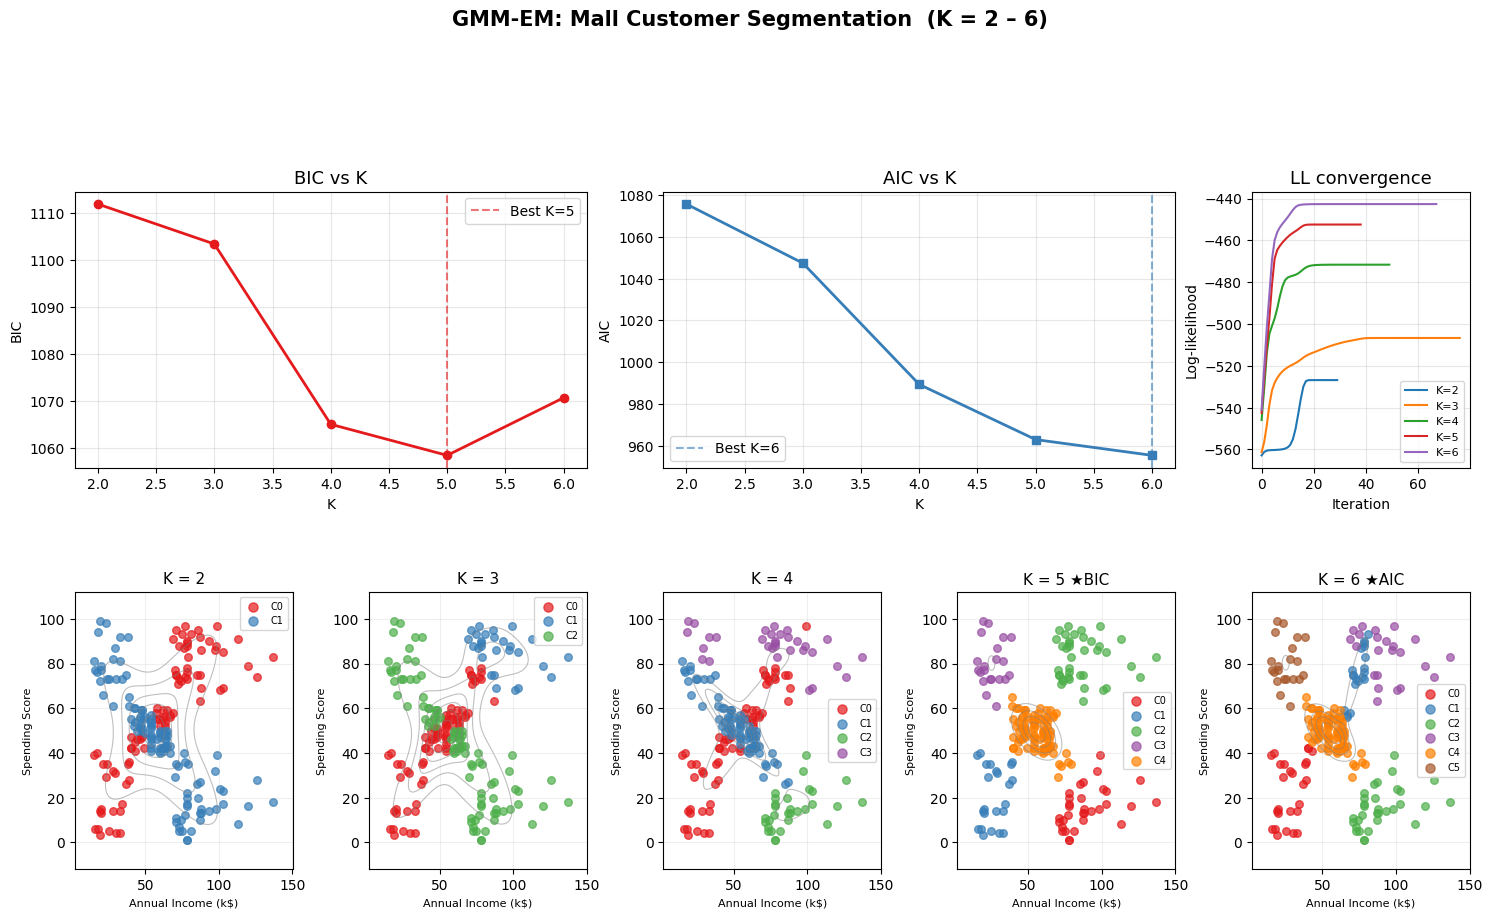

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import multivariate_normal
from sklearn.preprocessing import StandardScaler
import io, requests

# ── 1. Load data ──────────────────────────────────────────────────────────────
url = "https://raw.githubusercontent.com/kennedykwangari/Mall-Customer-Segmentation-Data/master/Mall_Customers.csv"
df = pd.read_csv(io.StringIO(requests.get(url).text))
df.columns = df.columns.str.strip()

# Use Annual Income and Spending Score (classic 2-D view)
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X_raw = df[features].values

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

# ── 2. Model selection helpers ────────────────────────────────────────────────
def bic(model, X):
    """BIC = -2·LL + p·ln(N)"""
    N, D = X.shape
    K = model.K
    # Free params: K-1 mixing weights + K*D means + K*D*(D+1)/2 cov entries
    n_params = (K - 1) + K * D + K * D * (D + 1) // 2
    return -2 * model.log_likelihoods[-1] + n_params * np.log(N)

def aic(model, X):
    N, D = X.shape
    K = model.K
    n_params = (K - 1) + K * D + K * D * (D + 1) // 2
    return -2 * model.log_likelihoods[-1] + 2 * n_params

# ── 3. Fit GMMs for K = 2 … 6 ────────────────────────────────────────────────
K_range = range(2, 7)
models, bic_scores, aic_scores = {}, {}, {}

for K in K_range:
    print(f"\n── K = {K} ──")
    gmm = GaussianMixtureEM(K=K, max_iter=200, tol=1e-6,init='kmeans').fit(X)
    models[K]    = gmm
    bic_scores[K] = bic(gmm, X)
    aic_scores[K] = aic(gmm, X)
    print(f"   Final LL : {gmm.log_likelihoods[-1]:.2f}")
    print(f"   BIC      : {bic_scores[K]:.2f}   AIC: {aic_scores[K]:.2f}")

best_K_bic = min(bic_scores, key=bic_scores.get)
best_K_aic = min(aic_scores, key=aic_scores.get)
print(f"\nBest K by BIC: {best_K_bic}   |   Best K by AIC: {best_K_aic}")

# ── 4. Plotting ───────────────────────────────────────────────────────────────
# Colour palette (up to 6 clusters)
COLORS = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628"]

# Grid: top row = model-selection curves, bottom rows = cluster scatter plots
n_models = len(K_range)
fig = plt.figure(figsize=(18, 14))
gs  = gridspec.GridSpec(3, n_models, figure=fig,
                        hspace=0.45, wspace=0.35)

# — 4a. BIC / AIC curves (span full top row) —
ax_bic = fig.add_subplot(gs[0, :2])
ax_aic = fig.add_subplot(gs[0, 2:4])

Ks = list(K_range)
ax_bic.plot(Ks, [bic_scores[k] for k in Ks], "o-", color="#e41a1c", lw=2)
ax_bic.axvline(best_K_bic, ls="--", color="#e41a1c", alpha=.6,
               label=f"Best K={best_K_bic}")
ax_bic.set_title("BIC vs K", fontsize=13)
ax_bic.set_xlabel("K"); ax_bic.set_ylabel("BIC")
ax_bic.legend(); ax_bic.grid(alpha=.3)

ax_aic.plot(Ks, [aic_scores[k] for k in Ks], "s-", color="#377eb8", lw=2)
ax_aic.axvline(best_K_aic, ls="--", color="#377eb8", alpha=.6,
               label=f"Best K={best_K_aic}")
ax_aic.set_title("AIC vs K", fontsize=13)
ax_aic.set_xlabel("K"); ax_aic.set_ylabel("AIC")
ax_aic.legend(); ax_aic.grid(alpha=.3)

# — 4b. Log-likelihood convergence (top-right) —
ax_ll = fig.add_subplot(gs[0, 4])
for K in K_range:
    ax_ll.plot(models[K].log_likelihoods, label=f"K={K}", lw=1.5)
ax_ll.set_title("LL convergence", fontsize=13)
ax_ll.set_xlabel("Iteration"); ax_ll.set_ylabel("Log-likelihood")
ax_ll.legend(fontsize=8); ax_ll.grid(alpha=.3)

# — 4c. Scatter plots for each K (rows 1–2) —
# Build a mesh for density contours in scaled space
x1 = np.linspace(X[:,0].min()-0.5, X[:,0].max()+0.5, 200)
x2 = np.linspace(X[:,1].min()-0.5, X[:,1].max()+0.5, 200)
xx, yy = np.meshgrid(x1, x2)
grid   = np.c_[xx.ravel(), yy.ravel()]

for i, K in enumerate(K_range):
    row = 1 + i // n_models   # rows 1 and 2
    col = i % n_models
    ax  = fig.add_subplot(gs[row, col])

    gmm    = models[K]
    labels = gmm.predict(X)

    # Scatter
    for k in range(K):
        mask = labels == k
        ax.scatter(X_raw[mask, 0], X_raw[mask, 1],
                   s=30, alpha=0.7, color=COLORS[k], label=f"C{k}")

    # Density contours (in original scale for axes, computed in scaled space)
    density = np.zeros(grid.shape[0])
    for k in range(K):
        density += gmm.pis[k] * multivariate_normal.pdf(
            grid, mean=gmm.means[k], cov=gmm.covs[k])
    density = density.reshape(xx.shape)

    # Map mesh back to original scale for display
    xx_orig = xx * scaler.scale_[0] + scaler.mean_[0]
    yy_orig = yy * scaler.scale_[1] + scaler.mean_[1]
    ax.contour(xx_orig, yy_orig, density, levels=6,
               colors="grey", linewidths=0.8, alpha=0.5)

    ax.set_title(f"K = {K}"
                 + (" ★BIC" if K == best_K_bic else "")
                 + (" ★AIC" if K == best_K_aic else ""),
                 fontsize=11)
    ax.set_xlabel("Annual Income (k$)", fontsize=8)
    ax.set_ylabel("Spending Score",     fontsize=8)
    ax.legend(fontsize=7, markerscale=1.2)
    ax.grid(alpha=.2)

plt.suptitle("GMM-EM: Mall Customer Segmentation  (K = 2 – 6)",
             fontsize=15, fontweight="bold", y=1.01)
plt.savefig("gmm_mall_segmentation.png", dpi=150, bbox_inches="tight")
plt.show()